[![Open in molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/adriansousapoza/tgmm/blob/main/notebooks/04_cem.py)

# Classification EM (CEM)

This notebook compares the **Classification EM (CEM)** algorithm with standard **Expectation-Maximization (EM)** for Gaussian Mixture Models. CEM inserts a hard classification step between the E-step and the M-step, so each point updates only the component it is most likely to belong to. In `tgmm` it is selected with `GaussianMixture(algorithm='cem')`.

**What you'll learn**

- How the C-step changes the EM iteration and what objective CEM maximizes
- How EM and CEM behave on heavily overlapping clusters (accuracy vs. speed)
- How they behave on well-separated clusters, where CEM's hard assignments lose little
- When CEM is a sensible choice

**Prerequisites:** [01 -- Gaussian Mixture Models](01_gmm.ipynb) and [02 -- EM Algorithm Walkthrough](02_em_algorithm.ipynb).

**See also:** the [Gaussian Mixture Model user guide](../user-guide/gaussian-mixture.md) for the other EM variants (`'sem'`, `'saem'`) and [14 -- Stochastic EM](14_stochastic_em.ipynb).

## Setup

The next cell imports what the notebook needs and fixes the random seeds. It expects `tgmm` to be importable: `pip install tgmm`, or `pip install -e .` from a clone of the repository. Opened with `marimo edit --sandbox`, the dependencies listed in the header of this file are installed automatically.

In [ ]:
import time

import numpy as np
import torch
import matplotlib.pyplot as plt


from tgmm import GaussianMixture, plot_gmm, dynamic_figsize, generate_gmm_data

plt.rcParams['figure.dpi'] = 100  # tgmm's theme uses 300 dpi; marimo embeds figures at 2x, so keep outputs small
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

## Overview

The CEM algorithm (Celeux and Govaert, 1992) is a variant of the EM algorithm that incorporates a **classification step (C-step)** between the E-step and M-step. This modification aims to maximize the **classification likelihood** rather than the traditional likelihood.

### CEM Algorithm Steps:

1. **E-step**: Calculate conditional probabilities $\tau_{ig}^{(r)}$ that observation $y_i$ belongs to cluster $g$
2. **C-step**: Assign each observation to one cluster using the MAP (Maximum A Posteriori) operator:
   $$z_{ig}^{(r+1)} = \begin{cases} 1 & \text{if } g = \arg\max_g \tau_{ig}^{(r)} \\ 0 & \text{otherwise} \end{cases}$$
3. **M-step**: Update parameters by maximizing the complete-data log-likelihood $L_C(\theta; y, z^{r+1})$

### Key Properties:

- **K-means-like**: Produces hard assignments rather than soft probabilistic assignments
- **Biased estimates**: Maximizes complete-data likelihood $L_C(\theta)$ rather than actual likelihood $L(\theta)$
- **Fast convergence**: CEM generally converges faster and is therefore computationally more efficient

### When to Use CEM:

- **Well-separated clusters**: When mixture components are well separated with similar proportions
- **Fast clustering**: When computational speed is more important than maximum likelihood estimates
- **Initialisation**: Can be used as an alternative initialisation if kmeans does not perform well

## Experiment 1: Overlapping Clusters

In this first experiment, we create **overlapping clusters** with varying sample sizes and covariance structures:

- **Component 1**: 1000 samples, spherical covariance (σ² = 1.0)
- **Component 2**: 1000 samples, spherical covariance (σ² = 0.5)
- **Component 3**: 1000 samples, diagonal covariance
- **Component 4**: 1000 samples, full covariance with correlation

This scenario tests how EM vs CEM handle **ambiguous cluster boundaries** where observations could reasonably belong to multiple clusters.

In [ ]:
def fit_and_evaluate_gmm(X_tensor, n_components, covariance_type='full', cem=False, seed=1, iters=10 if FAST else 20):
    """Fit a GMM with either EM or CEM `iters` times; return the best run and the average time, iterations and log-likelihood."""
    best_gmm = None
    average_time = 0
    average_iters = 0
    average_log_likelihood = 0
    for i in range(iters):
        gmm = GaussianMixture(n_components=n_components, covariance_type=covariance_type, tol=1e-10, reg_covar=1e-06, max_iter=1000, init_means='points', random_state=seed + i, device=device, algorithm='cem' if cem else 'em')
        start_time = time.time()
        gmm.fit(X_tensor)
        end_time = time.time()
        if best_gmm is None or gmm.lower_bound_ > best_gmm.lower_bound_:
            best_gmm = gmm
        average_time = average_time + (end_time - start_time)
        average_iters = average_iters + gmm.n_iter_
        average_log_likelihood = average_log_likelihood + gmm.lower_bound_
        print(f'Iteration {i + 1}/{iters} - Log-likelihood: {gmm.lower_bound_:.4f}, Iterations: {gmm.n_iter_}, Time: {end_time - start_time:.4f}s')
    return (best_gmm, average_time / iters, average_iters / iters, average_log_likelihood / iters)
_n_samples = [1000, 1000, 1000, 1000]
_centers = [np.array([0, 2]), np.array([2, -2]), np.array([0, 0]), np.array([2, 2])]
_covs = [1.0 * np.eye(2), 0.5 * np.eye(2), np.array([[2, 0], [0, 0.5]]), np.array([[0.2, 0.5], [0.5, 2]])]
_X_tensor, _y_tensor = generate_gmm_data(_centers, _covs, _n_samples, device=device, random_state=SEED)
X = _X_tensor.cpu().numpy()
labels = _y_tensor.cpu().numpy()
_legend_labels = [f'Component {i + 1}' for i in range(len(_n_samples))]
_n_features = X.shape[1]
_n_components = len(_n_samples)
print('Fitting GMM using standard EM algorithm...')
gmm_em, _time_em, _iters_em, _log_likelihood_em = fit_and_evaluate_gmm(_X_tensor, _n_components, cem=False, seed=SEED)
print('\nFitting GMM using Classification EM (CEM) algorithm...')
gmm_cem, _time_cem, _iters_cem, _log_likelihood_cem = fit_and_evaluate_gmm(_X_tensor, _n_components, cem=True, seed=SEED)
print('\n----- Performance Comparison -----')
print(f'EM:  Average Time: {_time_em:.3f}s, Average Iterations: {_iters_em:.0f}, Best Log-likelihood: {gmm_em.lower_bound_:.3f}, Average Log-likelihood: {_log_likelihood_em:.3f}')
print(f'CEM: Average Time: {_time_cem:.3f}s, Average Iterations: {_iters_cem:.0f}, Best Log-likelihood: {gmm_cem.lower_bound_:.3f}, Average Log-likelihood: {_log_likelihood_cem:.3f}')

Fitting GMM using standard EM algorithm...
Iteration 1/10 - Log-likelihood: -3.6400, Iterations: 146, Time: 0.1111s
Iteration 2/10 - Log-likelihood: -3.5059, Iterations: 90, Time: 0.0667s
Iteration 3/10 - Log-likelihood: -3.5059, Iterations: 208, Time: 0.1515s
Iteration 4/10 - Log-likelihood: -3.5059, Iterations: 280, Time: 0.2024s
Iteration 5/10 - Log-likelihood: -3.5059, Iterations: 108, Time: 0.0787s
Iteration 6/10 - Log-likelihood: -3.6400, Iterations: 89, Time: 0.0653s
Iteration 7/10 - Log-likelihood: -3.5059, Iterations: 230, Time: 0.1795s
Iteration 8/10 - Log-likelihood: -3.5059, Iterations: 131, Time: 0.0942s
Iteration 9/10 - Log-likelihood: -3.5059, Iterations: 311, Time: 0.2236s
Iteration 10/10 - Log-likelihood: -3.5059, Iterations: 142, Time: 0.1030s

Fitting GMM using Classification EM (CEM) algorithm...
Iteration 1/10 - Log-likelihood: -3.6532, Iterations: 42, Time: 0.0616s
Iteration 2/10 - Log-likelihood: -3.5445, Iterations: 37, Time: 0.0511s
Iteration 3/10 - Log-likelih

### Results Analysis: Overlapping Clusters

**Expected Behavior with Overlapping Clusters:**

When clusters overlap significantly, we expect to see:
- **CEM converges faster** but achieves a **worse log-likelihood on average** than EM
- **EM finds better local optima** but requires more iterations
- **CEM's hard assignments** may be suboptimal when cluster boundaries are ambiguous

This matches the theoretical expectation that CEM trades accuracy for speed when dealing with overlapping components.

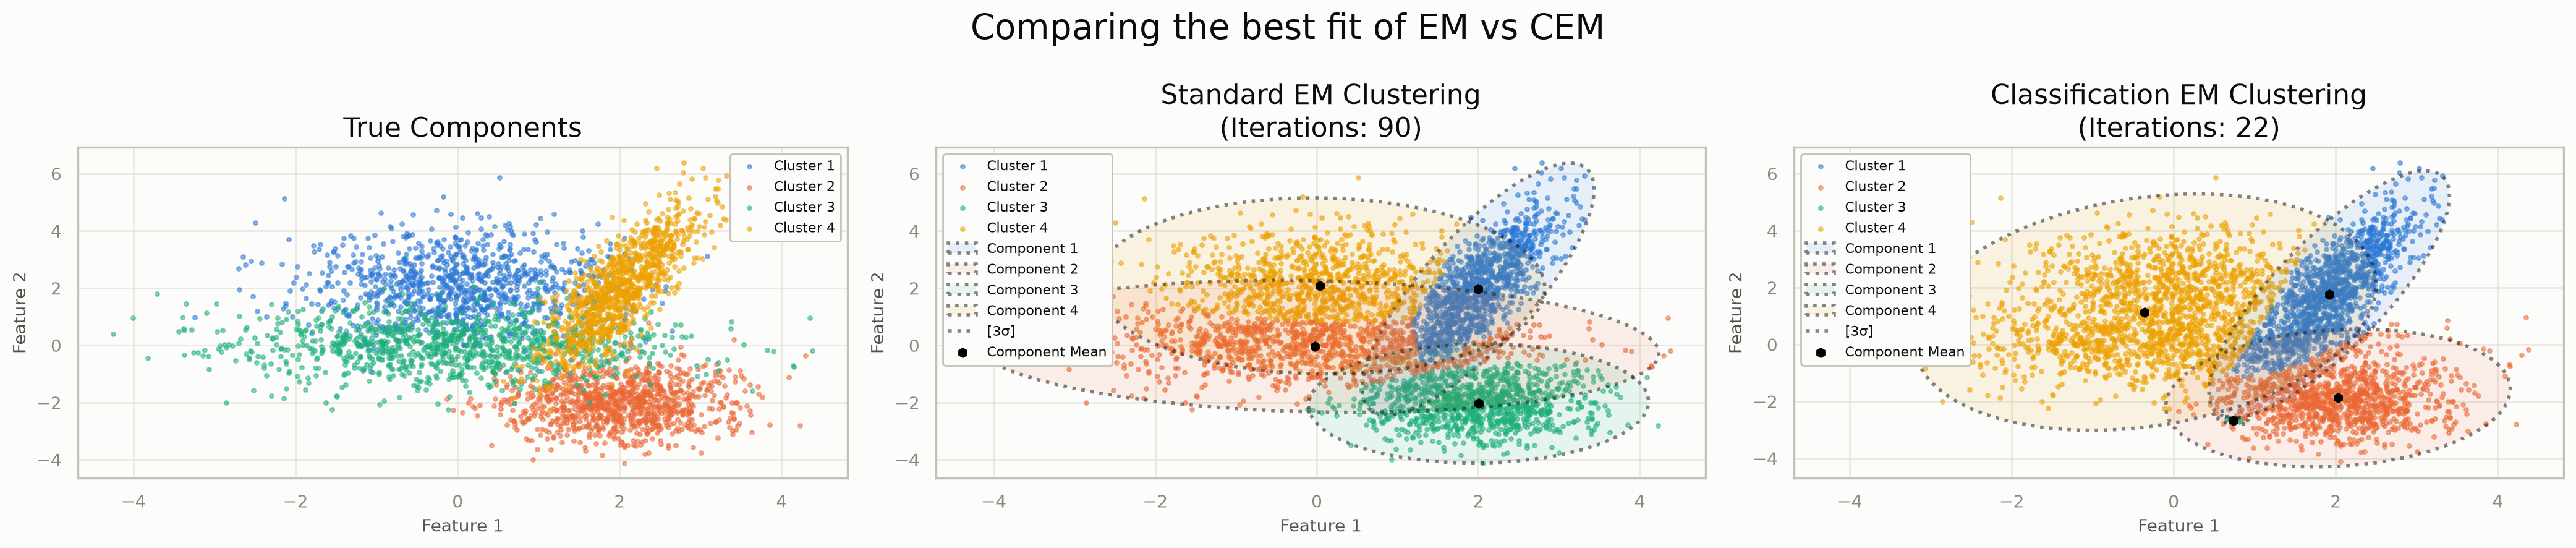

In [ ]:
_figsize = dynamic_figsize(1, 3)
_fig, _axes = plt.subplots(1, 3, figsize=_figsize)
_fig.suptitle('Comparing the best fit of EM vs CEM')
plot_gmm(X=X, true_labels=labels, ax=_axes[0], title='True Components', show_ellipses=False, show_means=False)
# Plot true labels
plot_gmm(X=X, gmm=gmm_em, ax=_axes[1], title=f'Standard EM Clustering\n(Iterations: {gmm_em.n_iter_})', color_by_cluster=True, match_labels_to_true=True, ellipse_std_devs=[3], ellipse_fill=True, ellipse_alpha=0.1)
plot_gmm(X=X, gmm=gmm_cem, ax=_axes[2], title=f'Classification EM Clustering\n(Iterations: {gmm_cem.n_iter_})', color_by_cluster=True, match_labels_to_true=True, ellipse_std_devs=[3], ellipse_fill=True, ellipse_alpha=0.1)
plt.tight_layout()
# Plot EM results
# Plot CEM results  
plt.gcf()

## Experiment 2: Well-Separated Clusters

In this second experiment, we create **well-separated clusters** by increasing the distance between cluster centers:

- **Component 1**: (0, 10) - 1000 samples, spherical covariance (σ² = 1.0)
- **Component 2**: (10, -20) - 1000 samples, spherical covariance (σ² = 0.5)
- **Component 3**: (0, 0) - 1000 samples, diagonal covariance
- **Component 4**: (10, 10) - 1000 samples, full covariance with correlation

This scenario tests the **ideal case for CEM** where cluster boundaries are clear and unambiguous. According to theory:

> "When the mixture components are well separated with similar proportions, the CEM algorithm is expected to provide a relevant clustering" (Celeux and Govaert, 1992)

**Expected Behavior:**
- **Similar final accuracy** for both EM and CEM
- **CEM converges much faster** due to clear cluster boundaries
- **Hard assignments are optimal** when clusters don't overlap

In [ ]:
_n_samples = [1000, 1000, 1000, 1000]
_centers = [np.array([0, 10]), np.array([10, -20]), np.array([0, 0]), np.array([10, 10])]
_covs = [1.0 * np.eye(2), 0.5 * np.eye(2), np.array([[2, 0], [0, 0.5]]), np.array([[0.2, 0.5], [0.5, 2]])]
_components = []
for _n, _center, _cov in zip(_n_samples, _centers, _covs):
    _samples = np.random.randn(_n, 2) @ np.linalg.cholesky(_cov).T + _center
    _components.append(_samples)
X_sep = np.vstack(_components)
labels_sep = np.concatenate([_i * np.ones(_n) for _i, _n in enumerate(_n_samples)])
_legend_labels = [f'Component {i + 1}' for i in range(len(_n_samples))]
_n_features = X_sep.shape[1]
_n_components = len(_n_samples)
_X_tensor = torch.tensor(X_sep, dtype=torch.float32, device=device)
print('Fitting GMM using standard EM algorithm...')
gmm_em_sep, _time_em, _iters_em, _log_likelihood_em = fit_and_evaluate_gmm(_X_tensor, _n_components, cem=False)
print('\nFitting GMM using Classification EM (CEM) algorithm...')
gmm_cem_sep, _time_cem, _iters_cem, _log_likelihood_cem = fit_and_evaluate_gmm(_X_tensor, _n_components, cem=True)
print('\n----- Performance Comparison -----')
print(f'EM:  Average Time: {_time_em:.3f}s, Average Iterations: {_iters_em:.0f}, Best Log-likelihood: {gmm_em_sep.lower_bound_:.3f}, Average Log-likelihood: {_log_likelihood_em:.3f}')
print(f'CEM: Average Time: {_time_cem:.3f}s, Average Iterations: {_iters_cem:.0f}, Best Log-likelihood: {gmm_cem_sep.lower_bound_:.3f}, Average Log-likelihood: {_log_likelihood_cem:.3f}')

Fitting GMM using standard EM algorithm...
Iteration 1/10 - Log-likelihood: -4.3985, Iterations: 63, Time: 0.0582s
Iteration 2/10 - Log-likelihood: -4.9642, Iterations: 264, Time: 0.2673s
Iteration 3/10 - Log-likelihood: -5.4878, Iterations: 115, Time: 0.1009s
Iteration 4/10 - Log-likelihood: -4.6065, Iterations: 104, Time: 0.1065s
Iteration 5/10 - Log-likelihood: -5.4880, Iterations: 108, Time: 0.0955s
Iteration 6/10 - Log-likelihood: -3.8097, Iterations: 9, Time: 0.0124s
Iteration 7/10 - Log-likelihood: -4.3986, Iterations: 34, Time: 0.0332s
Iteration 8/10 - Log-likelihood: -4.8841, Iterations: 25, Time: 0.0300s
Iteration 9/10 - Log-likelihood: -4.3985, Iterations: 73, Time: 0.0701s
Iteration 10/10 - Log-likelihood: -4.6064, Iterations: 92, Time: 0.0902s

Fitting GMM using Classification EM (CEM) algorithm...
Iteration 1/10 - Log-likelihood: -4.3983, Iterations: 45, Time: 0.0667s
Iteration 2/10 - Log-likelihood: -4.9638, Iterations: 17, Time: 0.0288s
Iteration 3/10 - Log-likelihood: 

### Results Analysis: Well-Separated Clusters

**Key Observations:**

The results confirm the theoretical predictions:
- **The best run of each algorithm reaches the same log-likelihood**, i.e. the same optimum. Averaged over the random restarts both are pulled down by a few poor local optima (some `init_means='points'` starts put two means in the same cluster), and neither is consistently better
- **CEM needs noticeably fewer iterations** (roughly 2-3x fewer here) and less time
- **The partitions are essentially identical** when clusters are well-separated

This demonstrates the **practical advantage of CEM** in scenarios with clear cluster structure. The hard assignment strategy becomes optimal when cluster boundaries are unambiguous.

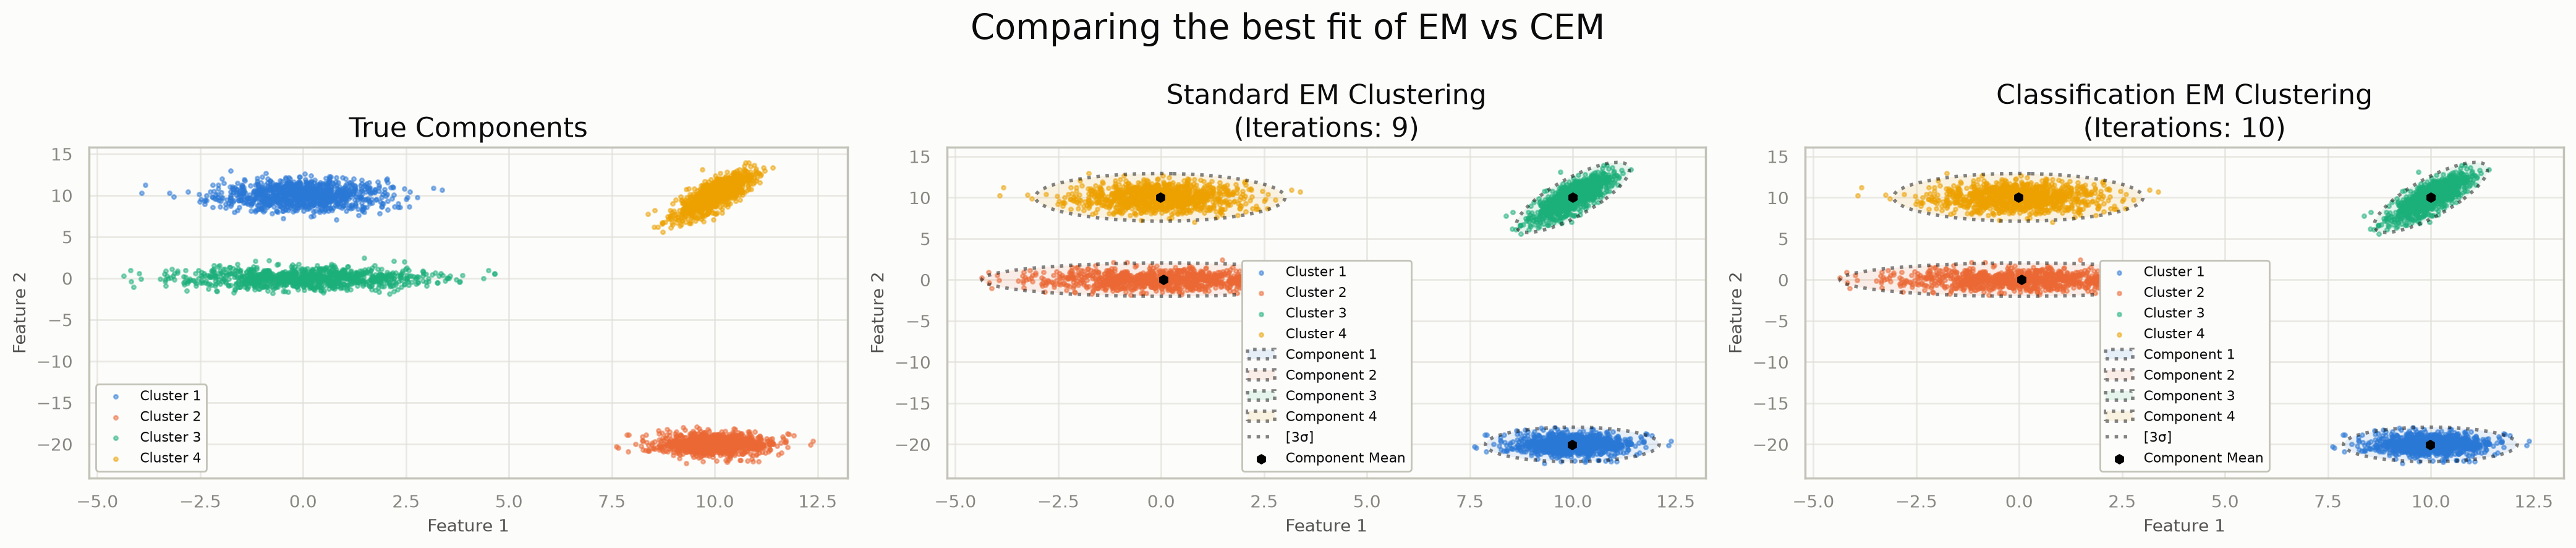

In [ ]:
_figsize = dynamic_figsize(1, 3)
_fig, _axes = plt.subplots(1, 3, figsize=_figsize)
_fig.suptitle('Comparing the best fit of EM vs CEM')
plot_gmm(X=X_sep, true_labels=labels_sep, ax=_axes[0], title='True Components', show_ellipses=False, show_means=False)
plot_gmm(X=X_sep, gmm=gmm_em_sep, ax=_axes[1], title=f'Standard EM Clustering\n(Iterations: {gmm_em_sep.n_iter_})', color_by_cluster=True, match_labels_to_true=True, ellipse_std_devs=[3], ellipse_fill=True, ellipse_alpha=0.1)
plot_gmm(X=X_sep, gmm=gmm_cem_sep, ax=_axes[2], title=f'Classification EM Clustering\n(Iterations: {gmm_cem_sep.n_iter_})', color_by_cluster=True, match_labels_to_true=True, ellipse_std_devs=[3], ellipse_fill=True, ellipse_alpha=0.1)
plt.tight_layout()
plt.gcf()

## Summary

- CEM replaces the soft E-step posterior with a hard assignment (the C-step) and maximizes the classification (complete-data) likelihood rather than the observed-data likelihood.
- With overlapping clusters, EM's soft assignments typically reach a higher log-likelihood, while CEM stops earlier but can settle on a cruder partition.
- With well-separated clusters the two reach comparable solutions and CEM needs fewer iterations.
- Use `algorithm='cem'` when speed or a crisp partition matters more than the exact maximum-likelihood fit.

**Next:** [05 -- Supervised Fitting](05_supervised_gmm.ipynb), which adds label information, or [14 -- Stochastic EM](14_stochastic_em.ipynb) for the stochastic variants.